#H M AHSAN HABIB KUSHAL
#CS 2203064
## Department of Computer Science and Engineering
###National Institute of Textile Engineering and Research

In [2]:
!pip install matplotlib

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

C:\Users\H. M. Ahsan Habib\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


###Data Loading

In [3]:
def load_data(filepath):
  data = np.loadtxt(filepath, delimiter=',', encoding='utf-8-sig')
  X = data[:, 0]
  y = data[:, 1]
  return X,y

X_train, y_train = load_data('restaurent_profit.txt')

In [4]:
print("x_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("\nFirst 5 x_train values:")
print(X_train[:5])
print("\nFirst 5 y_train values:")
print(y_train[:5])

x_train shape: (97,)
y_train shape: (97,)

First 5 x_train values:
[6.1101 5.5277 8.5186 7.0032 5.8598]

First 5 y_train values:
[17.592   9.1302 13.662  11.854   6.8233]


In [5]:
# Strip the BOM character and write back clean text
with open('restaurent_profit.txt', 'r', encoding='utf-8-sig') as f:
    clean_text = f.read()

with open('restaurent_profit.txt', 'w', encoding='utf-8') as f:
    f.write(clean_text)

###Computing The Cost Function

In [6]:
def compute_cost(X,y,w,b):
  m = X.shape[0]
  cost = np.sum(((w*X+b)-y)**2)/(2*m)
  return cost

###Compute Gradient

In [7]:
def compute_gradient(X,y,w,b):
  m = X.shape[0]
  f_wb = w * X + b
  dj_dw = (1/m) * np.sum((f_wb-y)*X)
  dj_db = (1/m)*np.sum(f_wb-y)
  return dj_dw, dj_db

###Compute Gradient Descent

In [8]:
def gradient_descent(X,y,w_in,b_in,alpha,num_iters):
  w = w_in
  b = b_in
  J_history = []

  for i in range(num_iters):
    dj_dw , dj_db = compute_gradient(X,y,w,b)
    w = w - alpha*dj_dw
    b = b - alpha*dj_db

    cost = compute_cost(X,y,w,b)
    J_history.append(cost)
  return w, b, J_history


##Model Training Parameters

In [9]:
initial_w = 0.0
initial_b = 0.0
iterations = 1500
alpha = 0.01

##Executing Gradient Descent

In [10]:
final_w,final_b,J_history = gradient_descent(
    X_train,y_train,initial_w,initial_b,alpha,iterations)

##Trained Parameters are:

In [11]:
print(f"Trained Weight (w): {final_w:.4f}")
print(f"Trained Bias (b):   {final_b:.4f}")

Trained Weight (w): 1.1664
Trained Bias (b):   -3.6303


## Cost vs. Iteration __ Plot

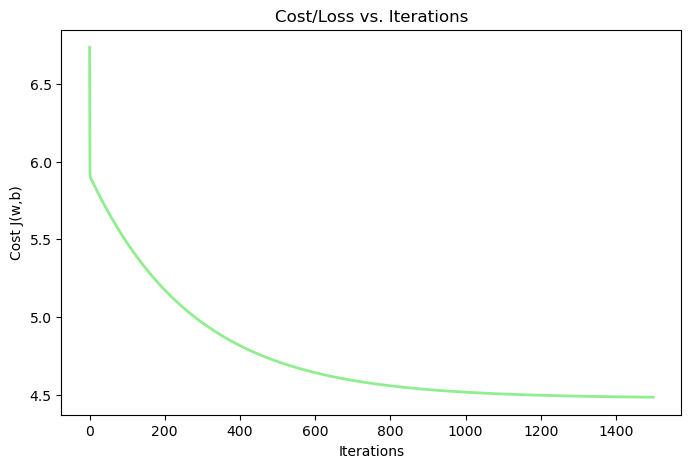

In [12]:
plt.figure(figsize=(8,5))
plt.plot(range(iterations), J_history, color = 'lightgreen', linewidth=2)
plt.xlabel('Iterations')
plt.ylabel('Cost J(w,b)')
plt.title('Cost/Loss vs. Iterations')
plt.show()

##New City Populations

In [13]:
predict_pop1 = 3.5  # 35,000 population
predict_pop2 = 7.0  # 70,000 population

##Prediction of Profit of new cities

In [14]:
pred1 = (final_w * predict_pop1 + final_b) * 10000
pred2 = (final_w * predict_pop2 + final_b) * 10000

In [15]:
print(f"Predicted profit for 35,000 population: ${pred1:.2f}")

Predicted profit for 35,000 population: $4519.77


In [16]:
print(f"Predicted profit for 70,000 population: ${pred2:.2f}")

Predicted profit for 70,000 population: $45342.45


##Scatter plot and The Regression Line

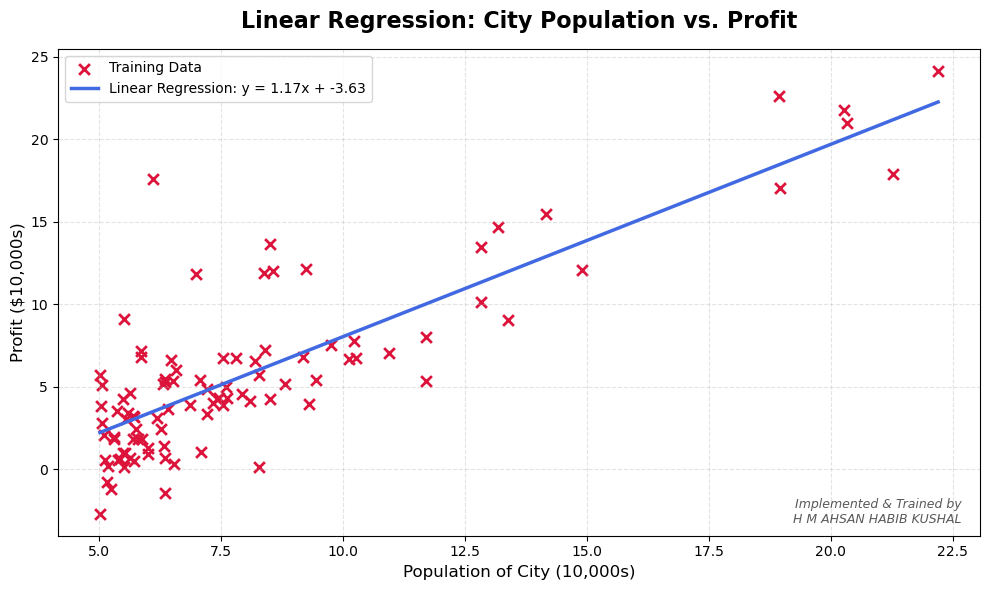

In [17]:
plt.figure(figsize=(10, 6))
plt.scatter(
    X_train,
    y_train,
    marker='x',
    color='crimson',
    s=60,
    linewidths=2,
    label='Training Data'
)
y_pred = final_w * X_train + final_b
sort_idx = X_train.flatten().argsort()
X_sorted = X_train.flatten()[sort_idx]
y_pred_sorted = y_pred.flatten()[sort_idx]
plt.plot(
    X_sorted,
    y_pred_sorted,
    color='royalblue',
    linewidth=2.5,
    label=f'Linear Regression: y = {final_w:.2f}x + {final_b:.2f}'
)

plt.title(
    'Linear Regression: City Population vs. Profit',
    fontsize=16,
    fontweight='bold',
    pad=15)
plt.xlabel(
    'Population of City (10,000s)',
    fontsize=12)
plt.ylabel(
    'Profit ($10,000s)',
    fontsize=12)
plt.grid(
    True,linestyle='--',alpha=0.35)
plt.legend(fontsize=10,frameon=True)
plt.tight_layout()
plt.text(0.98,0.02,
    '\nImplemented & Trained by\nH M AHSAN HABIB KUSHAL',transform=plt.gca().transAxes,
    fontsize=9,fontstyle='italic',ha='right',va='bottom',
    alpha=0.65)
plt.show()